# EMPLOYEE TURNOVER ANALYTICS

## PROBLEM DEFINITION:

Portobello Tech wants to predict employee turnover. As the ML Developer assigned to the HR Department, the task is to build ML programs that:

1. Perform data quality checks by checking for missing values, if any
2. Understand what factors contributed most to employee turnover at EDA
3. Perform clustering of employees who left based on their satisfaction and evaluation
4. Handle the left class imbalance using the SMOTE technique
5. Perform k-fold cross-validation model training and evaluate performance
6. Identify the best model and justify the evaluation metrics used
7. Suggest various retention strategies for targeted employees


## STEP 1: Import Data and Perform Data Quality Checks

In [1]:
# Import Libraries

import pandas as pd  
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score  
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")

# Read the HR data CSV file into a pandas DataFrame

df = pd.read_csv("HR_comma_sep.csv") 
df_rows, df_columns = df.shape
print("Dataset shape (rows, columns) : ", df.shape)  
print("\nPreview HR Dataset : ")  
df.head(10)  

Dataset shape (rows, columns) :  (14999, 10)

Preview HR Dataset : 


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
5,0.41,0.50,2,153,3,0,1,0,sales,low
6,0.10,0.77,6,247,4,0,1,0,sales,low
7,0.92,0.85,5,259,5,0,1,0,sales,low
8,0.89,1.00,5,224,5,0,1,0,sales,low
9,0.42,0.53,2,142,3,0,1,0,sales,low


In [2]:
print("\nDataset Information : \n=====================\n")
df.info()


Dataset Information : 

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


### 1.1 Check for missing values (and duplicate rows)

In [3]:
# Missing value check for every column

print("Missing values per column : \n")  
print(df.isnull().sum()) 
print("\nTotal missing values in the dataset : ", df.isnull().sum().sum())  

Missing values per column : 

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

Total missing values in the dataset :  0


In [4]:
# Duplicate row check - rows where all 10 columns are identical

df_unique = df.drop_duplicates()  
dup_count = len(df) - len(df_unique)  
print("\nTotal rows in the dataset  : ", df_rows)
print("Duplicate rows               : ", dup_count)  
print("Duplicate rows Percentage    : ", round(dup_count / len(df) * 100, 2),"%")  
print("\nDuplicate rows Employees Category count : ")  
print("\nEmployee Stayed : ", len(df[df['left'] == 0]) - len(df_unique[df_unique['left'] == 0])) # Employee category (0 = stayed, 1 = left)
print("Employee Left : ", len(df[df['left'] == 1]) - len(df_unique[df_unique['left'] == 1]))
#print(df['left'].value_counts() - df_unique['left'].value_counts()) 

# Build one text key per row from all 10 columns, then count how often each record appears

record_key = df['satisfaction_level'].astype(str)  
for col in df.columns[1:]:  
    record_key = record_key + "|" + df[col].astype(str)  
df['record_key'] = record_key
record_counts = df.groupby('record_key')['left'].count()  
record_counts = record_counts.sort_values(ascending=False)  
print("\nUnique records : ", len(record_counts))  
print("Most repeated records (number of copies) : ")  
print(record_counts.head(5).values) 

# Example: the most repeated record and all of its copies

top_key = record_counts.index[0] 
example_rows = df[df['record_key'] == top_key]  
df = df.drop('record_key', axis=1)  
print("\nExample of a repeated record and its copies : ")  
example_rows.drop('record_key', axis=1)  


Total rows in the dataset  :  14999
Duplicate rows               :  3008
Duplicate rows Percentage    :  20.05 %

Duplicate rows Employees Category count : 

Employee Stayed :  1428
Employee Left :  1580

Unique records :  11991
Most repeated records (number of copies) : 
[6 4 4 4 4]

Example of a repeated record and its copies : 


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
23,0.46,0.57,2,139,3,0,1,0,sales,low
396,0.46,0.57,2,139,3,0,1,0,sales,low
12023,0.46,0.57,2,139,3,0,1,0,sales,low
12396,0.46,0.57,2,139,3,0,1,0,sales,low
14234,0.46,0.57,2,139,3,0,1,0,sales,low
14607,0.46,0.57,2,139,3,0,1,0,sales,low


In [5]:
# Duplicate copies to be removed, (if kept - the same record can land in both the train set and the test set, and the test scores would look better than they really are)

# Keep the raw row count for reference

raw_rows = len(df)  

# The department column is named "sales" in the file; set the column names to match the problem statement

df.columns = ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'left', 'promotion_last_5years', 'Department', 'salary']
print("\nDataset Preview after column renaming : ")
display(df.head(10))

# Remove exact duplicate rows, keep the first copy

df = df.drop_duplicates().reset_index(drop=True)  

print("Rows before removing duplicates : ", raw_rows)  
print("Rows after removing duplicates  : ", len(df))  
print("Rows removed : ", raw_rows - len(df)) 
print("\nEmployees who stayed (0) and left (1) : ")  
print("Employee Stayed : ", len(df[df['left'] == 0]))
print("Employee Left : ", len(df[df['left'] == 1]))
print("\nShare of employees who left (%) : ", round(df['left'].mean() * 100, 2))  



Dataset Preview after column renaming : 


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
5,0.41,0.50,2,153,3,0,1,0,sales,low
6,0.10,0.77,6,247,4,0,1,0,sales,low
7,0.92,0.85,5,259,5,0,1,0,sales,low
8,0.89,1.00,5,224,5,0,1,0,sales,low
9,0.42,0.53,2,142,3,0,1,0,sales,low


Rows before removing duplicates :  14999
Rows after removing duplicates  :  11991
Rows removed :  3008

Employees who stayed (0) and left (1) : 
Employee Stayed :  10000
Employee Left :  1991

Share of employees who left (%) :  16.6


Observation:

1. There are no missing values in any of the 10 columns, so no imputation is needed.
2. 3,008 rows (20.05% of the dataset) are exact repeats of another row across all 10 columns. 1,580 of these repeats are employees who left and 1,428 are employees who stayed. Counting each full record shows 11,991 unique records, and the most repeated record (shown above) appears 6 times.
3. The department column is named "sales" in the file, it is renamed to "Department" to match the problem statement.
4. After removing duplicates, 11,991 employees remain: 10,000 stayed and 1,991 left. Only 16.6% of employees left, so the target column "left" is imbalanced. This is handled with SMOTE in Step 4.

## STEP 2: Understand what factors contributed most to employee turnover at EDA

In [6]:
# Compare the average of each numeric column for employees who stayed (0) and left (1)

numeric_cols = df.select_dtypes(include='number').columns.tolist()  
stayed_mean = df[df['left'] == 0][numeric_cols].mean()  
left_mean = df[df['left'] == 1][numeric_cols].mean()  
left_compare = np.round(pd.DataFrame({'Stayed (0)': stayed_mean, 'Left (1)': left_mean}), 3)  
print("Average values by left : \n")  
print(left_compare)  

Average values by left : 

                       Stayed (0)  Left (1)
satisfaction_level          0.667     0.440
last_evaluation             0.716     0.722
number_project              3.787     3.883
average_montly_hours      198.943   208.162
time_spend_company          3.262     3.881
Work_accident               0.174     0.053
left                        0.000     1.000
promotion_last_5years       0.020     0.004


In [7]:
# Leave rate (% of employees who left) by salary level

salary_rate = df.groupby('salary')['left'].agg(['count', 'sum', 'mean']) 
salary_rate.columns = ['Employees', 'Left', 'Leave_rate_%']  
salary_rate['Leave_rate_%'] = np.round(salary_rate['Leave_rate_%'] * 100, 2) 
print("Leave rate by salary : \n")  
print(salary_rate.sort_values('Leave_rate_%', ascending=False))  

# Leave rate (% of employees who left) by Department

dept_rate = df.groupby('Department')['left'].agg(['count', 'sum', 'mean'])  
dept_rate.columns = ['Employees', 'Left', 'Leave_rate_%'] 
dept_rate['Leave_rate_%'] = np.round(dept_rate['Leave_rate_%'] * 100, 2)  
print("\nLeave rate by department : \n")  
print(dept_rate.sort_values('Leave_rate_%', ascending=False))  

# Leave rate (% of employees who left) by years in the company

tenure_rate = df.groupby('time_spend_company')['left'].agg(['count', 'sum', 'mean'])  
tenure_rate.columns = ['Employees', 'Left', 'Leave_rate_%']  
tenure_rate['Leave_rate_%'] = np.round(tenure_rate['Leave_rate_%'] * 100, 2) 
print("\nLeave rate by years in the company : \n")  
print(tenure_rate)  

Leave rate by salary : 

        Employees  Left  Leave_rate_%
salary                               
low          5740  1174         20.45
medium       5261   769         14.62
high          990    48          4.85

Leave rate by department : 

             Employees  Left  Leave_rate_%
Department                                
hr                 601   113         18.80
accounting         621   109         17.55
technical         2244   390         17.38
support           1821   312         17.13
sales             3239   550         16.98
marketing          673   112         16.64
IT                 976   158         16.19
product_mng        686   110         16.03
RandD              694    85         12.25
management         436    52         11.93

Leave rate by years in the company : 

                    Employees  Left  Leave_rate_%
time_spend_company                               
2                        2910    31          1.07
3                        5190   874         16.84

Observation:

From the comparison tables, it is identified the following

- Satisfaction factor: employees who left average 0.440 satisfaction against 0.667 for those who stayed.
- Employees who left worked more hours on average (208.162 against 198.943).
- Time in the company is not a straight-line effect. Leaving peaks at 3 to 6 years, highest at 5 years (45.39%), while employees with 2 years or with 7 or more years rarely or never leave. The difference in average years (3.881 against 3.262) only reflects leavers being concentrated in these middle years.
- Promotions are rare for leavers (0.004 against 0.020)
- Employees who left had fewer work accidents (0.053 against 0.174). This is an association only, and the dataset does not explain why.
- Last evaluation is almost the same in both groups (0.722 against 0.716), so the average alone hides a pattern. The distribution checks in 2.2 show it.
- Salary factor : the leave rate is 20.45% for low salary, 14.62% for medium and 4.85% for high.
- Department has a smaller effect: from 18.80% (hr) down to 11.93% (management).

### 2.1 Heatmap of the correlation matrix between all numerical features

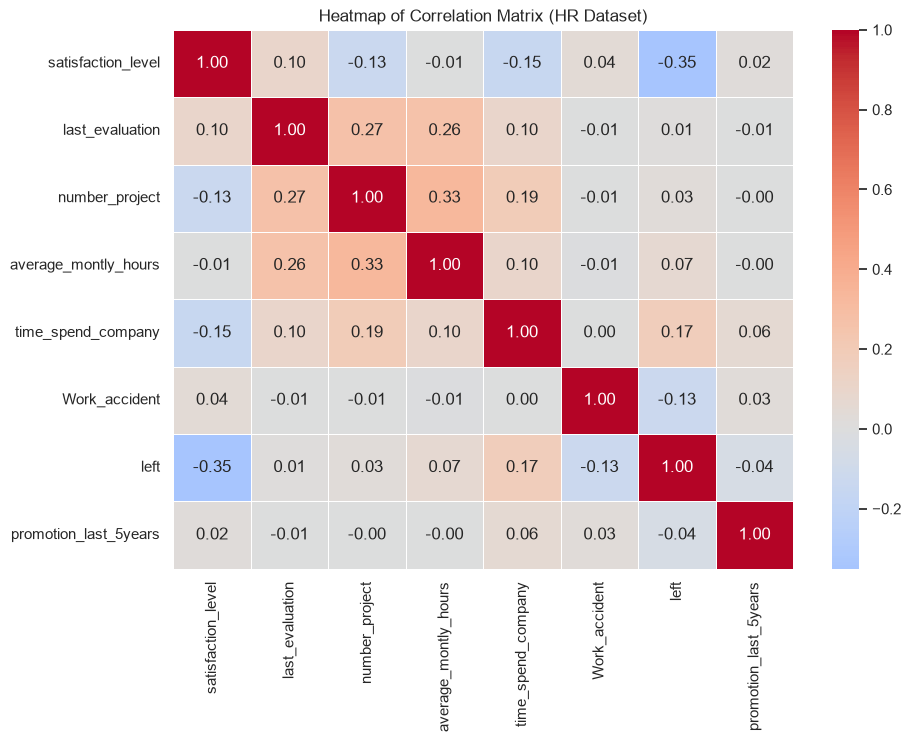

Correlation of each column with left employees (sorted) : 

satisfaction_level      -0.35
Work_accident           -0.13
promotion_last_5years   -0.04
last_evaluation          0.01
number_project           0.03
average_montly_hours     0.07
time_spend_company       0.17
Name: left, dtype: float64


In [8]:
# Correlation matrix of all numeric columns (Employee left is included as 0/1)

correlation = df[numeric_cols].corr()  

plt.figure(figsize=(10, 7))  
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f", center=0, linewidths=0.5)  
plt.title('Heatmap of Correlation Matrix (HR Dataset)')  
plt.show()  

print("Correlation of each column with left employees (sorted) : \n")  
print(np.round(correlation['left'].drop('left').sort_values(), 2))  

Observation:

From the Visualization of the Correlation Heatmap, it is identified the following ( Note - Correlation shows link not cause )

- satisfaction_level has the strongest link with left (-0.35): lower satisfaction goes with leaving.
- time_spend_company (0.17) has a positive link and Work_accident (-0.13) has a negative link with left. Both are associations only: the leave rate by years table above shows the years link is not a straight line (it peaks at 5 years), and the data does not explain why employees with work accidents left less often.
- last_evaluation (0.01), number_project (0.03) and average_montly_hours (0.07) have almost no straight-line link with left.

### 2.2 Distribution plots of Employee Satisfaction, Employee Evaluation and Employee Average Monthly Hours

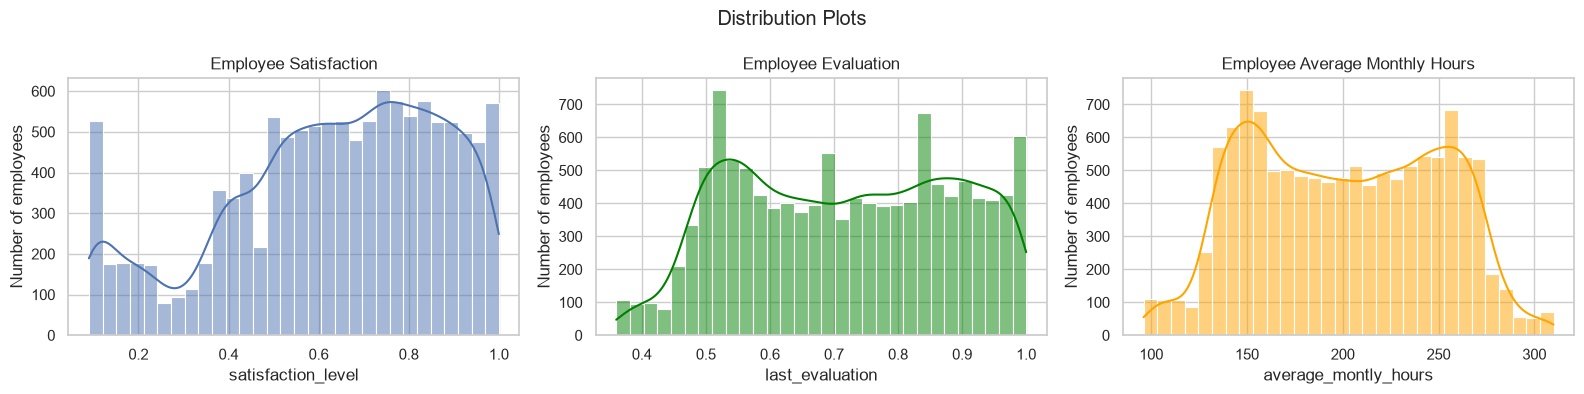

Summary statistics : 

       satisfaction_level  last_evaluation  average_montly_hours
count            11991.00         11991.00              11991.00
mean                 0.63             0.72                200.47
std                  0.24             0.17                 48.73
min                  0.09             0.36                 96.00
25%                  0.48             0.57                157.00
50%                  0.66             0.72                200.00
75%                  0.82             0.86                243.00
max                  1.00             1.00                310.00


In [9]:
# Distribution plots of satisfaction, evaluation and average monthly hours

fig, axes = plt.subplots(1, 3, figsize=(16, 4))  

sns.histplot(df['satisfaction_level'], bins=30, kde=True, ax=axes[0])  
axes[0].set_title('Employee Satisfaction')  
axes[0].set_xlabel('satisfaction_level')  
axes[0].set_ylabel('Number of employees')  

sns.histplot(df['last_evaluation'], bins=30, kde=True, ax=axes[1], color='green')  
axes[1].set_title('Employee Evaluation')  
axes[1].set_xlabel('last_evaluation')  
axes[1].set_ylabel('Number of employees')  

sns.histplot(df['average_montly_hours'], bins=30, kde=True, ax=axes[2], color='orange')  
axes[2].set_title('Employee Average Monthly Hours')  
axes[2].set_xlabel('average_montly_hours')  
axes[2].set_ylabel('Number of employees')  

fig.suptitle('Distribution Plots')  
plt.tight_layout()  
plt.show()  

print("Summary statistics : \n")
print(np.round(df[['satisfaction_level', 'last_evaluation', 'average_montly_hours']].describe(), 2)) 


Leave rate by satisfaction_band : 

                   Employees  Left  Leave_rate_%
satisfaction_band                               
(0.0, 0.2]               994   523         52.62
(0.2, 0.5]              2390   891         37.28
(0.5, 0.7]              3372    52          1.54
(0.7, 1.0]              5235   525         10.03

Leave rate by evaluation_band : 

                 Employees  Left  Leave_rate_%
evaluation_band                               
(0.3, 0.5]            1430   398         27.83
(0.5, 0.6]            2393   482         20.14
(0.6, 0.8]            3883   150          3.86
(0.8, 1.0]            4285   961         22.43

Leave rate by hours_band : 

            Employees  Left  Leave_rate_%
hours_band                               
(90, 150]        2328   603         25.90
(150, 250]       7253   683          9.42
(250, 280]       2067   457         22.11
(280, 320]        343   248         72.30


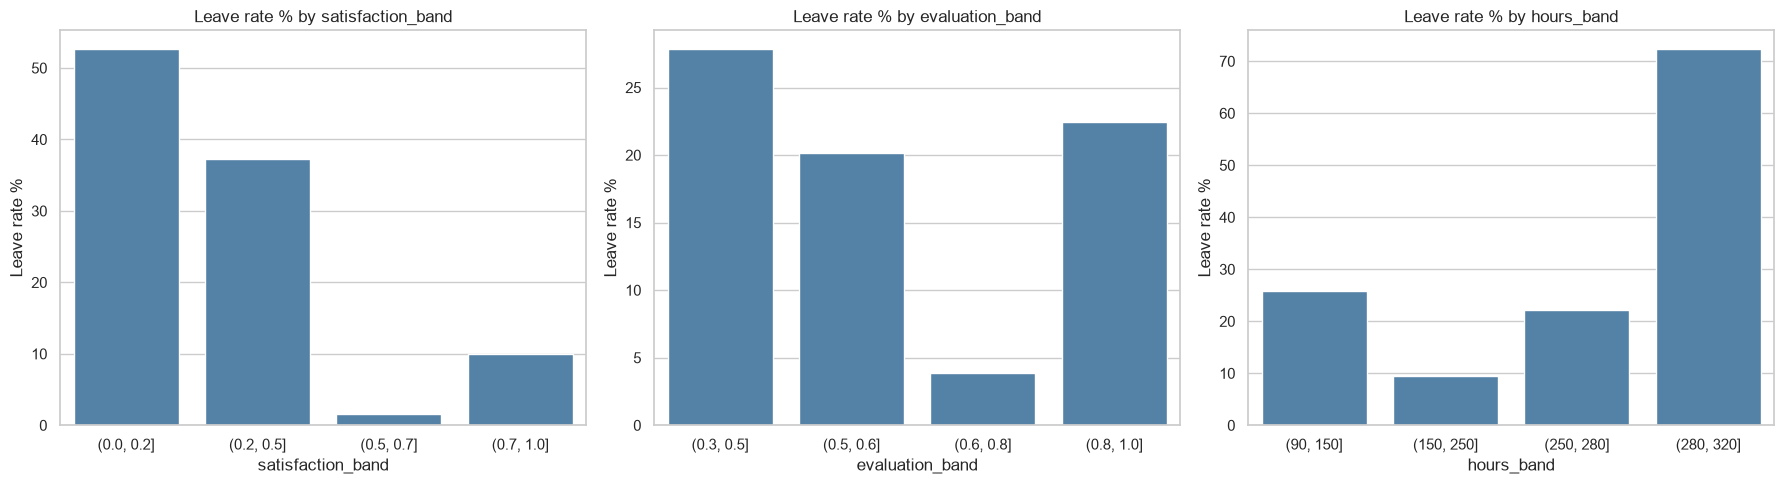

In [10]:
# Check the leave rate inside ranges of each column, to back the findings

df['satisfaction_band'] = pd.cut(df['satisfaction_level'], bins=[0, 0.2, 0.5, 0.7, 1.0])
df['evaluation_band'] = pd.cut(df['last_evaluation'], bins=[0.3, 0.5, 0.6, 0.8, 1.0])
df['hours_band'] = pd.cut(df['average_montly_hours'], bins=[90, 150, 250, 280, 320])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, band in enumerate(['satisfaction_band', 'evaluation_band', 'hours_band']):
    band_rate = df.groupby(band)['left'].agg(['count', 'sum', 'mean'])
    band_rate.columns = ['Employees', 'Left', 'Leave_rate_%']
    band_rate['Leave_rate_%'] = np.round(band_rate['Leave_rate_%'] * 100, 2)
    print("\nLeave rate by", band, ": \n")
    print(band_rate)

    # bar chart of the leave rate % for each range
    ax = sns.barplot(x=band_rate.index.astype(str), y=band_rate['Leave_rate_%'], color='steelblue', ax=axes[i])
    ax.set_title("Leave rate % by " + band)
    ax.set_xlabel(band)
    ax.set_ylabel("Leave rate %")

plt.tight_layout()
plt.show()

# remove the helper band columns so they do not enter the model

df = df.drop(['satisfaction_band', 'evaluation_band', 'hours_band'], axis=1)

Observation:

From the Visualization of the Distribution Plots of satisfaction, evaluation and average monthly hours, it is identified the following

- Satisfaction Band : 
    -   most employees score between 0.48 and 0.82 (median 0.66), with a separate spike of very unhappy employees near 0.1. 
    -   In the 0 to 0.2 band, 52.62% left, and in the 0.2 to 0.5 band 37.28% left, against 1.54% in the 0.5 to 0.7 band.
- Evaluation Band : 
    -   the plot has two humps, one in the low 0.5s and one in the high 0.8s (median 0.72). 
    -   Both ends have high leave rates: 27.83% for scores of 0.5 and below and 22.43% for scores above 0.8, against 3.86% in the 0.6 to 0.8 band.
- Average monthly hours Band : 
    -   the plot also has two humps, one near 150 hours and one near 250 to 260 hours (median 200). 
    -   Under-worked staff (150 hours or less) leave at 25.90%, and staff above 280 hours leave at 72.30%, against 9.42% in the 150 to 250 band.
- It can be summarized that employees who leave sit at the extremes: either low performers with little work, or high performers with heavy hours.

### 2.3 Bar plot of employee project count for employees who left and stayed

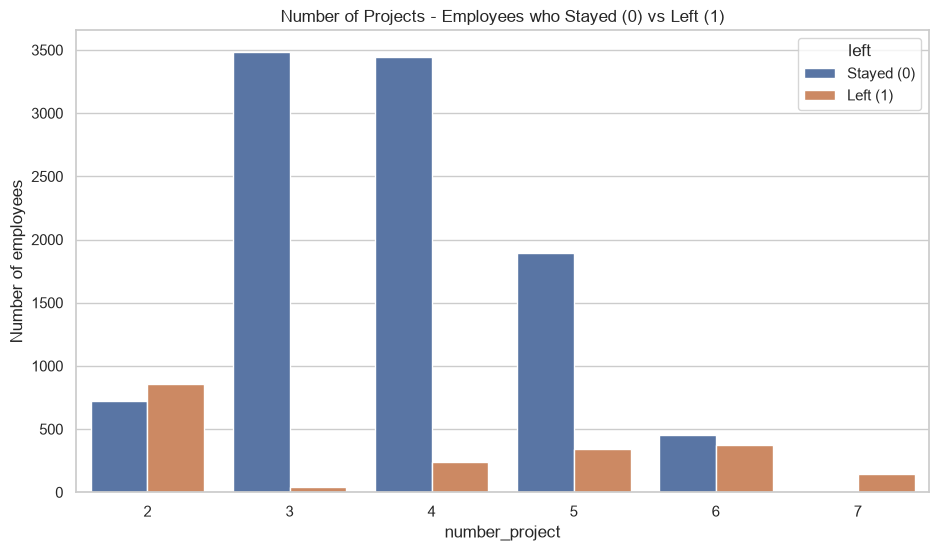

Employees who stayed and left by number of projects : 

                Employees  Stayed  Left  Leave_rate_%
number_project                                       
2                    1582     725   857         54.17
3                    3520    3482    38          1.08
4                    3685    3448   237          6.43
5                    2233    1890   343         15.36
6                     826     455   371         44.92
7                     145       0   145        100.00


In [11]:
# Bar plot of project count for employees who stayed and left

plt.figure(figsize=(11, 6))
ax = sns.countplot(data=df, x='number_project', hue='left')  
plt.title('Number of Projects - Employees who Stayed (0) vs Left (1)')
plt.xlabel('number_project')
plt.ylabel('Number of employees')
plt.legend(title='left', labels=['Stayed (0)', 'Left (1)'])
plt.show()

project_rate = df.groupby('number_project')['left'].agg(['count', 'sum', 'mean'])
project_rate.columns = ['Employees', 'Left', 'Leave_rate_%']
project_rate['Stayed'] = project_rate['Employees'] - project_rate['Left']
project_rate['Leave_rate_%'] = np.round(project_rate['Leave_rate_%'] * 100, 2)
print("Employees who stayed and left by number of projects : \n")
print(project_rate[['Employees', 'Stayed', 'Left', 'Leave_rate_%']])

In [12]:
# Check project count stats to back the findings

proj_profile = df.groupby('number_project')[['satisfaction_level', 'last_evaluation', 'average_montly_hours']].mean()
proj_profile = np.round(proj_profile, 3)
print("\nAverage profile by number of projects : \n")
print(proj_profile)


Average profile by number of projects : 

                satisfaction_level  last_evaluation  average_montly_hours
number_project                                                           
2                            0.499            0.585               164.812
3                            0.689            0.717               197.338
4                            0.694            0.736               203.872
5                            0.671            0.750               209.125
6                            0.315            0.766               230.392
7                            0.117            0.864               275.621


Observation:

From the Visualization of the Project Count Bar Plot, it is identified the following

- Employees with only 2 projects have a high leave rate (54.17%, 857 of 1,582). They also have the lowest average evaluation (0.585), the fewest monthly hours (164.812) and low satisfaction (0.499). This points to under-used or disengaged employees, not a comfortable workload.
- 3 projects is the safest workload, with only 1.08% leaving (38 of 3,520), followed by 4 projects (6.43%). These groups have the highest satisfaction (0.689 and 0.694).
- From 5 projects up, the leave rate climbs again: 15.36% at 5, 44.92% at 6, and all 145 employees with 7 projects left (100.00%). Average hours rise from 209.125 at 5 projects to 275.621 at 7, while satisfaction falls from 0.671 to 0.117, which points to overload and burnout.
- Inference: there are two different leaving groups. Employees with too little work (2 projects) and those with too much (6 to 7 projects) both leave far more, while 3 to 4 projects is the balanced range. The data shows the link, not the reason.

## STEP 3: Clustering of employees who left based on satisfaction and evaluation

### 3.1 Choose columns satisfaction_level, last_evaluation and left

In [13]:
# Choose satisfaction_level, last_evaluation and left, then keep only employees who left

cluster_data = df[['satisfaction_level', 'last_evaluation', 'left']]
left_employee = cluster_data[cluster_data['left'] == 1]  
print("Employees who left : ", left_employee.shape[0])  
left_employee.head(10)  

Employees who left :  1991


,satisfaction_level,last_evaluation,left
0,0.38,0.53,1
1,0.80,0.86,1
2,0.11,0.88,1
3,0.72,0.87,1
4,0.37,0.52,1
5,0.41,0.50,1
6,0.10,0.77,1
7,0.92,0.85,1
8,0.89,1.00,1
9,0.42,0.53,1


### 3.2 K-means clustering of employees who left the company into 3 clusters

In [14]:
# K-means with 3 clusters on satisfaction and evaluation

X_cluster = left_employee[['satisfaction_level', 'last_evaluation']]
kmeans = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=123)  
left_employee['cluster'] = kmeans.fit_predict(X_cluster)  

print("Silhouette score (k = 3) : ", round(silhouette_score(X_cluster, left_employee['cluster']), 3))  

centers = pd.DataFrame(np.round(kmeans.cluster_centers_, 3), columns=['satisfaction_level', 'last_evaluation'])
centers['employees'] = left_employee['cluster'].value_counts().sort_index()
print("\nCluster centers and size : \n")
print(centers)

Silhouette score (k = 3) :  0.795

Cluster centers and size : 

   satisfaction_level  last_evaluation  employees
0               0.111            0.869        534
1               0.806            0.913        555
2               0.410            0.517        902


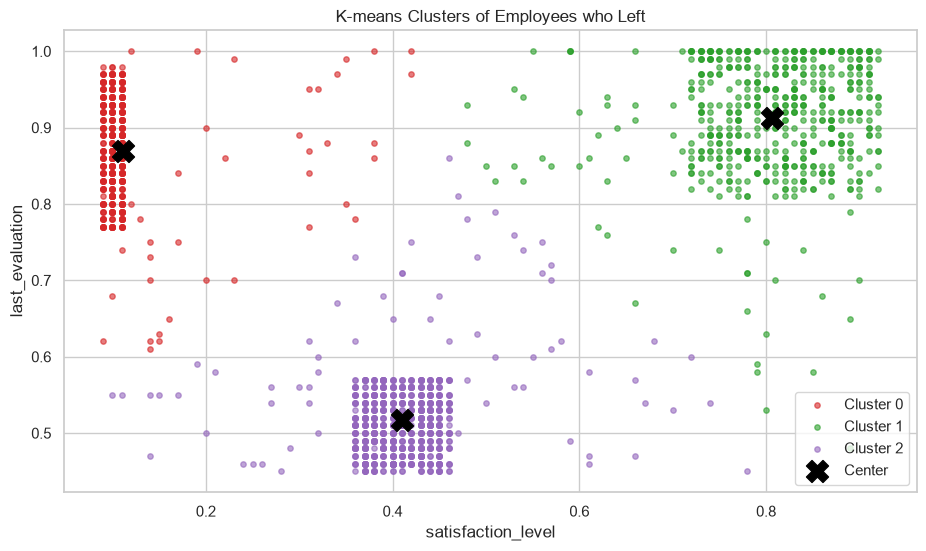

In [15]:
# Scatter plot of the 3 clusters with their centers

plt.figure(figsize=(11, 6))
colors = ['tab:red', 'tab:green', 'tab:purple']
for k in range(3):
    part = left_employee[left_employee['cluster'] == k] 
    plt.scatter(part['satisfaction_level'], part['last_evaluation'], s=15, alpha=0.6, color=colors[k], label=f'Cluster {k}') 
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=250, marker='X', color='black', label='Center')
plt.title('K-means Clusters of Employees who Left')
plt.xlabel('satisfaction_level')
plt.ylabel('last_evaluation')
plt.legend()
plt.show()

In [16]:
# Cluster profile: averages of the main work columns for each cluster

cluster_profile = df[df['left'] == 1][['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company']]
cluster_profile['cluster'] = left_employee['cluster']
np.round(cluster_profile.groupby('cluster')[['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company']].mean(), 2)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company
cluster,,,,,
0,0.11,0.87,6.12,271.84,4.08
1,0.81,0.91,4.51,242.00,5.01
2,0.41,0.52,2.17,149.64,3.07


Observation:

From the Visualization of the K-means Clusters of employees who left, it is identified the following

- The three groups are well separated, with a silhouette score of 0.795.
- Cluster 0 (534 employees): very low satisfaction (0.11) but high evaluation (0.87). They had 6.12 projects and 271.84 monthly hours on average.
- Cluster 1 (555 employees): high satisfaction (0.81) and the highest evaluation (0.91), with 4.51 projects, 242.00 hours and 5.01 years in the company on average.
- Cluster 2 (902 employees, the largest): middle satisfaction (0.41) and low evaluation (0.52), with only 2.17 projects and 149.64 hours on average.

### 3.3 Employee Cluster observation based on satisfaction and evaluation factors

- Cluster 0 - "Overworked and burned out": strong performers carrying too many projects and very long hours, with almost no satisfaction left. Workload balance, recognition and managers checking for burnout early could help.
- Cluster 1 - "Happy high performers who still left": they were satisfied and rated highly, and had been in the company about 5 years. Career paths, promotions and pay reviews for top talent could help.
- Cluster 2 - "Disengaged and under-used": low workload, low rating and below-average satisfaction. Better role fit, training and clear goals could help.

## STEP 4: Handle the left class imbalance using the SMOTE technique

### 4.1. Pre-process the data by converting categorical columns to numerical columns

#### 4.1.1 Separating categorical variables and numeric variables

In [17]:
categorical_cols = df.select_dtypes(exclude='number').columns.tolist()
numeric_cols = df.select_dtypes(include='number').drop('left', axis=1).columns.tolist()
print("Categorical columns : ", categorical_cols)
print("Numeric columns     : ", numeric_cols)

Categorical columns :  ['Department', 'salary']
Numeric columns     :  ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years']


#### 4.1.2 Applying get_dummies() to the categorical variables

In [18]:
dummies = pd.get_dummies(df[categorical_cols], dtype=int)
print("\nDummy columns created : ", dummies.shape[1])
print(dummies.columns.tolist())


Dummy columns created :  13
['Department_IT', 'Department_RandD', 'Department_accounting', 'Department_hr', 'Department_management', 'Department_marketing', 'Department_product_mng', 'Department_sales', 'Department_support', 'Department_technical', 'salary_high', 'salary_low', 'salary_medium']


#### 4.1.3 Combining categorical variables and numeric variables

In [19]:
X = pd.concat([df[numeric_cols], dummies], axis=1)
y = df['left']
print("\nFeature table shape (rows, columns) : ", X.shape)
X.head()


Feature table shape (rows, columns) :  (11991, 20)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,Department_IT,Department_RandD,Department_accounting,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0


### 4.2 Stratified split of the dataset into train and test (80:20, random_state=123)

In [20]:
# Stratified 80:20 split so train and test keep the same share of leavers

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123, stratify=y)

print("Train shape : ", X_train.shape, "  Test shape : ", X_test.shape)
print("\nShare of leavers in full data (%) : ", round(y.mean() * 100, 2))
print("Share of leavers in train (%)     : ", round(y_train.mean() * 100, 2))
print("Share of leavers in test (%)      : ", round(y_test.mean() * 100, 2))

Train shape :  (9592, 20)   Test shape :  (2399, 20)

Share of leavers in full data (%) :  16.6
Share of leavers in train (%)     :  16.61
Share of leavers in test (%)      :  16.59


### 4.3 Upsample the train dataset using SMOTE (imblearn)

Train before SMOTE - stayed (left = 0) :  7999
Train before SMOTE - left   (left = 1) :  1593

Train after SMOTE - stayed (left = 0)  :  7999
Train after SMOTE - left   (left = 1)  :  7999

Train rows before SMOTE :  9592   after SMOTE :  15998


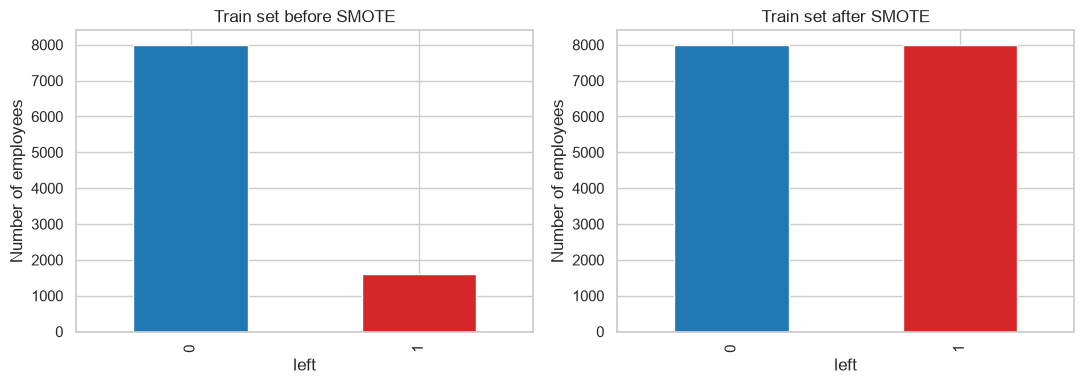

In [21]:
# Scale the features (fit on train only), then upsample the train set with SMOTE
# The test set is never resampled, so it stays a real-world sample

scaler = StandardScaler()  
X_train_sc = scaler.fit_transform(X_train) 
X_test_sc = scaler.transform(X_test)

smote = SMOTE(random_state=123)
X_train_sm, y_train_sm = smote.fit_resample(X_train_sc, y_train)

print("Train before SMOTE - stayed (left = 0) : ", len(y_train[y_train == 0]))
print("Train before SMOTE - left   (left = 1) : ", len(y_train[y_train == 1]))
print("\nTrain after SMOTE - stayed (left = 0)  : ", len(y_train_sm[y_train_sm == 0]))
print("Train after SMOTE - left   (left = 1)  : ", len(y_train_sm[y_train_sm == 1]))
print("\nTrain rows before SMOTE : ", len(y_train), "  after SMOTE : ", len(y_train_sm))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y_train.value_counts().sort_index().plot(kind='bar', ax=axes[0], color=['tab:blue', 'tab:red'])
axes[0].set_title('Train set before SMOTE')
axes[0].set_xlabel('left')
axes[0].set_ylabel('Number of employees')
y_train_sm.value_counts().sort_index().plot(kind='bar', ax=axes[1], color=['tab:blue', 'tab:red'])
axes[1].set_title('Train set after SMOTE')
axes[1].set_xlabel('left')
axes[1].set_ylabel('Number of employees')
plt.tight_layout()
plt.show()

Observation:

- Before SMOTE the train set had 7,999 employees who stayed and 1,593 who left.
- After SMOTE both classes have 7,999 rows, and the train set grows from 9,592 to 15,998 rows.
- The test set (2,399 employees, 16.59% leavers) is not resampled, so it still reflects the real share of leavers.

## STEP 5: 5-fold cross-validation model training and performance evaluation

In [22]:
# 5-fold stratified cross-validation on the original train set
# Scaler and SMOTE sit inside the pipeline, so each validation fold holds only real employees

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
cv_metrics = ['recall', 'precision', 'roc_auc', 'accuracy']

def run_cv(model, name):
    pipe = Pipeline([('scaler', StandardScaler()), ('smote', SMOTE(random_state=123)), ('model', model)])
    result = {}
    for metric in cv_metrics:
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=metric)
        result[metric] = scores.mean()
        print(f"{name} - 5-fold CV {metric} : ", np.round(scores, 4), " mean : ", round(scores.mean(), 4))
    return result

# classification report shown as a heatmap, built from the confusion matrix with the metric formulas
# precision = TP / (TP + FP), recall = TP / (TP + FN), f1 = 2 * precision * recall / (precision + recall)

def plot_report(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm[0][0], cm[0][1], cm[1][0], cm[1][1]
    p0, r0 = tn / (tn + fn), tn / (tn + fp)
    p1, r1 = tp / (tp + fp), tp / (tp + fn)
    f0, f1 = 2 * p0 * r0 / (p0 + r0), 2 * p1 * r1 / (p1 + r1)
    s0, s1 = tn + fp, fn + tp
    report = pd.DataFrame({'precision': [p0, p1, (p0 + p1) / 2, (p0 * s0 + p1 * s1) / (s0 + s1)],
                           'recall': [r0, r1, (r0 + r1) / 2, (r0 * s0 + r1 * s1) / (s0 + s1)],
                           'f1-score': [f0, f1, (f0 + f1) / 2, (f0 * s0 + f1 * s1) / (s0 + s1)]},
                          index=['0', '1', 'macro avg', 'weighted avg'])
    plt.figure(figsize=(6, 3.5))
    sns.heatmap(report, annot=True, fmt=".3f", cmap='Blues', vmin=0, vmax=1)
    plt.title(title)
    plt.show()

cv_results = {}
test_pred = {}
test_prob = {}

### 5.1 Logistic Regression with 5-fold CV and classification report

Logistic Regression - 5-fold CV recall :  [0.8464 0.8652 0.7925 0.827  0.815 ]  mean :  0.8292
Logistic Regression - 5-fold CV precision :  [0.4085 0.4138 0.4019 0.4235 0.429 ]  mean :  0.4153
Logistic Regression - 5-fold CV roc_auc :  [0.8438 0.8454 0.8313 0.8385 0.8438]  mean :  0.8406
Logistic Regression - 5-fold CV accuracy :  [0.7707 0.7738 0.7701 0.7847 0.7888]  mean :  0.7776

Logistic Regression Classification Report (test set) : 
              precision    recall  f1-score   support

           0     0.9562    0.7636    0.8491      2001
           1     0.4095    0.8241    0.5471       398

    accuracy                         0.7737      2399
   macro avg     0.6828    0.7939    0.6981      2399
weighted avg     0.8655    0.7737    0.7990      2399



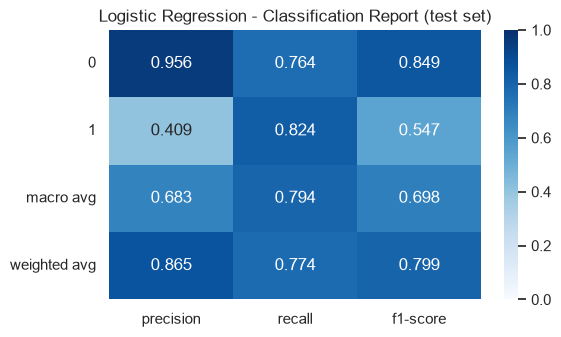

In [23]:
# Logistic Regression: 5-fold CV, then fit on the SMOTE train set and test on the untouched test set

cv_results['Logistic Regression'] = run_cv(LogisticRegression(max_iter=1000, random_state=123), 'Logistic Regression')

log_reg = LogisticRegression(max_iter=1000, random_state=123)
log_reg.fit(X_train_sm, y_train_sm)
test_pred['Logistic Regression'] = log_reg.predict(X_test_sc)
test_prob['Logistic Regression'] = log_reg.predict_proba(X_test_sc)[:, 1]

print("\nLogistic Regression Classification Report (test set) : ")
print(classification_report(y_test, test_pred['Logistic Regression'], digits=4))
plot_report(y_test, test_pred['Logistic Regression'], 'Logistic Regression - Classification Report (test set)')

Observation:

From the Visualization of the Logistic Regression Classification Report, it is identified the following

- Mean 5-fold CV recall is 0.8292, but CV precision is only 0.4153.
- On the test set, recall for leavers (class 1) is 0.8241, but precision is 0.4095: fewer than half of the employees flagged as leavers actually left.
- Accuracy is 0.7737. A straight-line model cannot capture the U-shaped patterns found in the EDA, such as projects, hours and evaluation, where both low and high values mean risk.

### 5.2 Random Forest Classifier with 5-fold CV and classification report

Random Forest - 5-fold CV recall :  [0.9091 0.9122 0.9025 0.9182 0.906 ]  mean :  0.9096
Random Forest - 5-fold CV precision :  [0.9508 0.9765 0.9897 0.9799 0.9731]  mean :  0.974
Random Forest - 5-fold CV roc_auc :  [0.9826 0.9843 0.9701 0.9861 0.9814]  mean :  0.9809
Random Forest - 5-fold CV accuracy :  [0.9771 0.9818 0.9823 0.9833 0.9802]  mean :  0.9809

Random Forest Classification Report (test set) : 
              precision    recall  f1-score   support

           0     0.9808    0.9945    0.9876      2001
           1     0.9703    0.9020    0.9349       398

    accuracy                         0.9792      2399
   macro avg     0.9755    0.9483    0.9612      2399
weighted avg     0.9790    0.9792    0.9789      2399



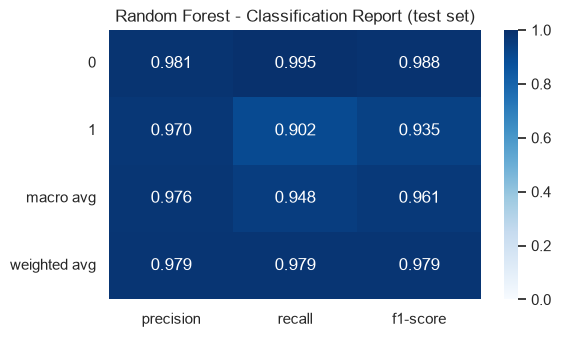

In [24]:
# Random Forest: 5-fold CV, then fit on the SMOTE train set and test on the untouched test set

cv_results['Random Forest'] = run_cv(RandomForestClassifier(random_state=123), 'Random Forest')
rf_model = RandomForestClassifier(random_state=123)
rf_model.fit(X_train_sm, y_train_sm)
test_pred['Random Forest'] = rf_model.predict(X_test_sc)
test_prob['Random Forest'] = rf_model.predict_proba(X_test_sc)[:, 1]

print("\nRandom Forest Classification Report (test set) : ")
print(classification_report(y_test, test_pred['Random Forest'], digits=4))
plot_report(y_test, test_pred['Random Forest'], 'Random Forest - Classification Report (test set)')

Observation:

From the Visualization of the Random Forest Classification Report, it is identified the following

- Mean 5-fold CV recall is 0.9096 and CV precision is 0.9740.
- On the test set, recall for leavers is 0.9020 and precision is 0.9703, with accuracy 0.9792.
- The tree-based model captures the non-linear patterns far better than Logistic Regression.

### 5.3 Gradient Boosting Classifier with 5-fold CV and classification report

Gradient Boosting - 5-fold CV recall :  [0.9436 0.9342 0.9151 0.9308 0.9279]  mean :  0.9303
Gradient Boosting - 5-fold CV precision :  [0.8985 0.9085 0.9238 0.8889 0.9164]  mean :  0.9072
Gradient Boosting - 5-fold CV roc_auc :  [0.9869 0.9893 0.9781 0.9877 0.9858]  mean :  0.9856
Gradient Boosting - 5-fold CV accuracy :  [0.9729 0.9734 0.9734 0.9692 0.9739]  mean :  0.9726

Gradient Boosting Classification Report (test set) : 
              precision    recall  f1-score   support

           0     0.9830    0.9815    0.9822      2001
           1     0.9077    0.9146    0.9111       398

    accuracy                         0.9704      2399
   macro avg     0.9454    0.9480    0.9467      2399
weighted avg     0.9705    0.9704    0.9704      2399



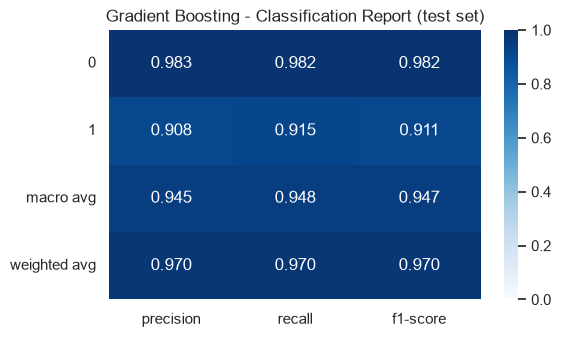

In [25]:
# Gradient Boosting: 5-fold CV, then fit on the SMOTE train set and test on the untouched test set

cv_results['Gradient Boosting'] = run_cv(GradientBoostingClassifier(random_state=123), 'Gradient Boosting')

gb_model = GradientBoostingClassifier(random_state=123)
gb_model.fit(X_train_sm, y_train_sm)
test_pred['Gradient Boosting'] = gb_model.predict(X_test_sc)
test_prob['Gradient Boosting'] = gb_model.predict_proba(X_test_sc)[:, 1]

print("\nGradient Boosting Classification Report (test set) : ")
print(classification_report(y_test, test_pred['Gradient Boosting'], digits=4)) 
plot_report(y_test, test_pred['Gradient Boosting'], 'Gradient Boosting - Classification Report (test set)')

Observation:

From the Visualization of the Gradient Boosting Classification Report, it is identified the following

- Mean 5-fold CV recall is 0.9303, the highest of the three models, and CV precision is 0.9072.
- On the test set, recall for leavers is 0.9146 and precision is 0.9077, with accuracy 0.9704.
- It catches more leavers than Random Forest at the cost of slightly lower precision.

In [26]:
# Mean 5-fold CV scores of the three models

model_names = list(cv_results.keys())
cv_table = np.round(pd.DataFrame([cv_results[name] for name in model_names], index=model_names), 4)
cv_table.columns = ['CV_recall', 'CV_precision', 'CV_roc_auc', 'CV_accuracy']
print("Mean 5-fold CV scores (train set) : \n")
print(cv_table)

Mean 5-fold CV scores (train set) : 

                     CV_recall  CV_precision  CV_roc_auc  CV_accuracy
Logistic Regression     0.8292        0.4153      0.8406       0.7776
Random Forest           0.9096        0.9740      0.9809       0.9809
Gradient Boosting       0.9303        0.9072      0.9856       0.9726


Observation:

From the 5-fold CV summary, it is identified the following

- Gradient Boosting has the highest mean CV recall (0.9303) and the highest mean CV ROC AUC (0.9856).
- Random Forest has the highest CV precision (0.9740) and CV accuracy (0.9809).
- Logistic Regression is the weakest model, with CV ROC AUC 0.8406.

## STEP 6: Identify the best model and justify the evaluation metrics used

### 6.1 ROC/AUC for each model and ROC curves

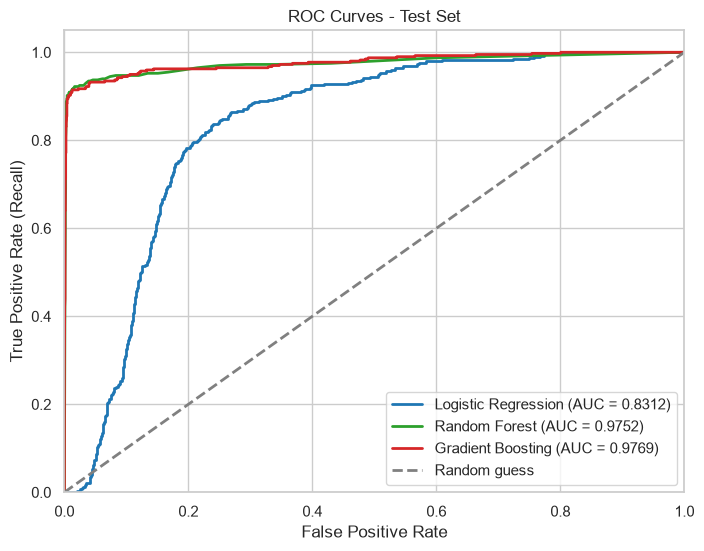

Logistic Regression test AUC :  0.8312
Random Forest test AUC :  0.9752
Gradient Boosting test AUC :  0.9769


In [27]:
# ROC curve and AUC of each model on the test set

auc_scores = {}
plt.figure(figsize=(8, 6))
for name, color in zip(test_prob.keys(), ['tab:blue', 'tab:green', 'tab:red']):
    fpr, tpr, thresholds = roc_curve(y_test, test_prob[name])
    auc_scores[name] = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC = {auc_scores[name]:.4f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Random guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves - Test Set')
plt.legend(loc='lower right')
plt.show()

for name in auc_scores:
    print(f"{name} test AUC : ", round(auc_scores[name], 4))

Observation:

From the Visualization of the ROC Curves, it is identified the following

- Gradient Boosting has the highest test AUC (0.9769), closely followed by Random Forest (0.9752).
- Logistic Regression is clearly lower (0.8312). Its curve sits well below the other two at every false positive rate.
- Both tree ensembles rank leavers above stayers very reliably at almost any threshold.

### 6.2 Confusion matrix for each model

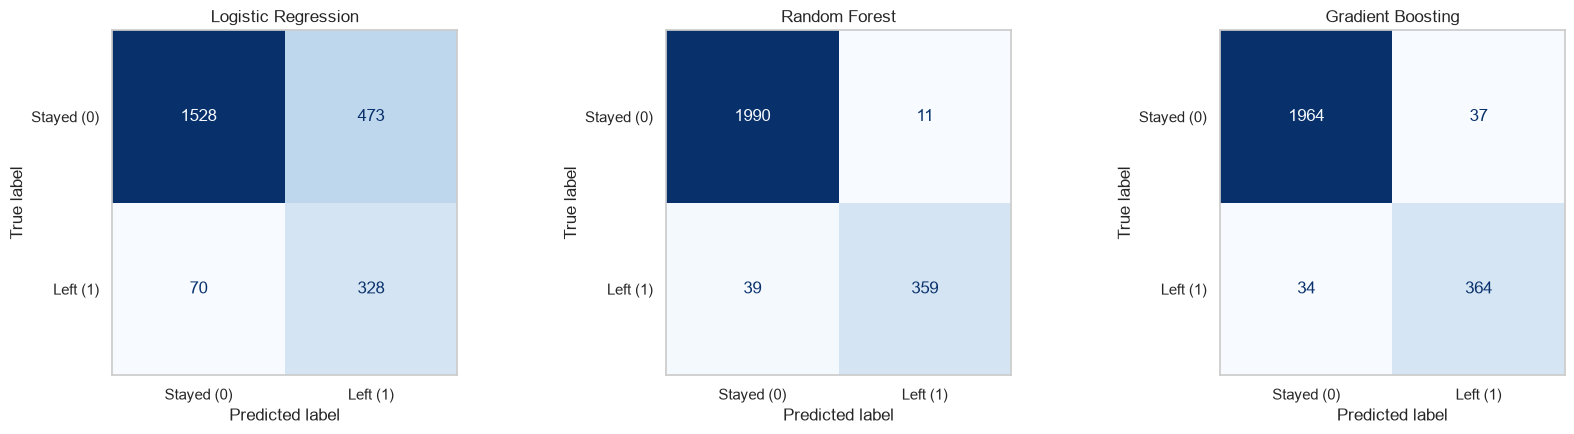

Logistic Regression : TN = 1528, FP = 473, FN = 70, TP = 328
Random Forest : TN = 1990, FP = 11, FN = 39, TP = 359
Gradient Boosting : TN = 1964, FP = 37, FN = 34, TP = 364


In [28]:
# Confusion matrix of each model on the test set

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
cm_values = {}
for ax, name in zip(axes, test_pred.keys()):
    cm = confusion_matrix(y_test, test_pred[name]) 
    cm_values[name] = cm
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stayed (0)', 'Left (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

for name, cm in cm_values.items():
    tn, fp, fn, tp = cm[0][0], cm[0][1], cm[1][0], cm[1][1]
    print(f"{name} : TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

Observation:

From the Visualization of the Confusion Matrices, it is identified the following (test set: 2,001 stayed, 398 left)

- Logistic Regression: catches 328 leavers but misses 70 (FN) and raises 473 false alarms (FP).
- Random Forest: catches 359 leavers, misses 39 and raises only 11 false alarms.
- Gradient Boosting: catches 364 leavers, the most of the three, misses the fewest (34) and raises 37 false alarms.

### 6.3 Metric from the confusion matrix: Recall or Precision?

Observation: Recall

- Precision = TP / (TP + FP): of the employees flagged as leaving, how many actually leave.
- Recall = TP / (TP + FN): of the employees who actually leave, how many the model catches.
- In turnover prediction, a missed leaver (False Negative) is the costly error: the company loses a trained employee with no chance to act, and pays for hiring and onboarding a replacement.
- A false alarm (False Positive) only costs a retention conversation or a small benefit for someone who would have stayed anyway, which is cheap and often still useful.
- Therefore "Recall" of class 1 (left) is the main metric. Precision and AUC are checked as support, so that the model does not flag almost everyone just to raise recall.

In [29]:
# Compare the models on the chosen metric (recall of class 1) and supporting metrics

comparison = pd.DataFrame({'CV_recall': cv_table['CV_recall'], 'CV_roc_auc': cv_table['CV_roc_auc']}) 
for name, cm in cm_values.items():
    tn, fp, fn, tp = cm[0][0], cm[0][1], cm[1][0], cm[1][1]
    comparison.loc[name, 'Test_recall'] = round(tp / (tp + fn), 4)
    comparison.loc[name, 'Test_precision'] = round(tp / (tp + fp), 4)
    comparison.loc[name, 'Test_AUC'] = round(auc_scores[name], 4)
    comparison.loc[name, 'Leavers_missed_FN'] = fn
comparison['Leavers_missed_FN'] = comparison['Leavers_missed_FN'].astype(int)
comparison

,CV_recall,CV_roc_auc,Test_recall,Test_precision,Test_AUC,Leavers_missed_FN
Logistic Regression,0.8292,0.8406,0.8241,0.4095,0.8312,70
Random Forest,0.9096,0.9809,0.9020,0.9703,0.9752,39
Gradient Boosting,0.9303,0.9856,0.9146,0.9077,0.9769,34


In [30]:
# Pick the model with the highest 5-fold CV recall

best_name = comparison.index[np.argmax(comparison['CV_recall'])]
print("Best model by 5-fold CV recall : ", best_name)

Best model by 5-fold CV recall :  Gradient Boosting


### BEST MODEL : Gradient Boosting Classifier

Justification :

- Highest recall, the chosen metric, in 5-fold CV (0.9303) and on the test set (0.9146). It misses only 34 of 398 leavers, against 39 for Random Forest and 70 for Logistic Regression.
- Highest ROC AUC in CV (0.9856) and on the test set (0.9769), so it also ranks employees by risk best, which is what the risk zones in Step 7 depend on.
- Precision stays high (0.9077 on test), so HR is not flooded with false alarms. Random Forest has better precision (0.9703), but the gap in recall matters more for the business goal.
- CV and test scores are close (recall 0.9303 against 0.9146), so the model is not overfitting the train data.

## STEP 7: Suggest retention strategies for targeted employees

### 7.1 Predict the probability of employee turnover in the test data using the best model

In [31]:
# Probability of turnover for each test employee using the best model

best_model = {'Logistic Regression': log_reg, 'Random Forest': rf_model, 'Gradient Boosting': gb_model}[best_name]
print("Model used : ", best_name)

test_result = pd.DataFrame({'satisfaction_level': X_test['satisfaction_level'],
                            'last_evaluation': X_test['last_evaluation'],
                            'number_project': X_test['number_project'],
                            'average_montly_hours': X_test['average_montly_hours'],
                            'left_actual': y_test.values}) 
test_result['turnover_probability'] = best_model.predict_proba(X_test_sc)[:, 1]
print("\nTurnover probability summary : ")
print(np.round(test_result['turnover_probability'].describe(), 4))
test_result[['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours',
             'left_actual', 'turnover_probability']].head(10)

Model used :  Gradient Boosting

Turnover probability summary : 
count    2399.0000
mean        0.1985
std         0.3414
min         0.0009
25%         0.0148
50%         0.0309
75%         0.1248
max         0.9925
Name: turnover_probability, dtype: float64


,satisfaction_level,last_evaluation,number_project,average_montly_hours,left_actual,turnover_probability
8569,0.82,0.95,6,191,0,0.585296
5747,0.18,0.86,5,267,0,0.451707
3985,0.63,0.98,4,160,0,0.024414
1776,0.43,0.51,2,149,1,0.906010
10499,0.51,0.98,4,245,0,0.048805
1533,0.83,0.92,4,235,1,0.937287
8554,0.20,0.90,3,218,0,0.165535
6154,0.74,0.84,3,239,0,0.021748
4230,0.98,0.50,4,264,0,0.015180
7910,0.80,1.00,3,177,0,0.025387


Observation:

Using Gradient Boosting, every test employee now has a turnover probability. The median probability is 0.0309 and the mean is 0.1985. Most employees have a very low score, and a smaller group has a very high score, close to the maximum of 0.9925.

### 7.2 Categorize employees into four risk zones and suggest retention strategies

Zones: 
- Safe Zone (Green) score < 20%
- Low-Risk Zone (Yellow) 20% to under 60%
- Medium-Risk Zone (Orange) 60% to under 90%
- High-Risk Zone (Red) 90% and above.

In [32]:
# Assign each test employee to a risk zone

zone_labels = ['Safe Zone (Green)', 'Low-Risk Zone (Yellow)', 'Medium-Risk Zone (Orange)', 'High-Risk Zone (Red)']
test_result['risk_zone'] = pd.cut(test_result['turnover_probability'], bins=[0, 0.2, 0.6, 0.9, np.inf], right=False, labels=zone_labels)

print("Scores exactly on a boundary (0.2, 0.6, 0.9) : ", test_result['turnover_probability'].isin([0.2, 0.6, 0.9]).sum())
print("Employees without a zone : ", test_result['risk_zone'].isnull().sum())

zone_counts = test_result.groupby('risk_zone')['left_actual'].agg(['count', 'sum'])
zone_counts.columns = ['Employees', 'Actually_left']
zone_means = test_result.groupby('risk_zone')[['satisfaction_level', 'number_project', 'average_montly_hours']].mean()
zone_means.columns = ['Avg_satisfaction', 'Avg_projects', 'Avg_monthly_hours']
zone_table = pd.concat([zone_counts, zone_means], axis=1)
zone_table['Share_of_test_%'] = np.round(zone_table['Employees'] / zone_table['Employees'].sum() * 100, 2)
zone_table['Actual_leave_rate_%'] = np.round(zone_table['Actually_left'] / zone_table['Employees'] * 100, 2)
np.round(zone_table, 2)

Scores exactly on a boundary (0.2, 0.6, 0.9) :  0
Employees without a zone :  0


,Employees,Actually_left,Avg_satisfaction,Avg_projects,Avg_monthly_hours,Share_of_test_%,Actual_leave_rate_%
risk_zone,,,,,,,
Safe Zone (Green),1890,26,0.68,3.78,198.44,78.78,1.38
Low-Risk Zone (Yellow),121,9,0.46,4.06,212.09,5.04,7.44
Medium-Risk Zone (Orange),39,22,0.68,3.82,222.97,1.63,56.41
High-Risk Zone (Red),349,341,0.43,3.78,205.31,14.55,97.71


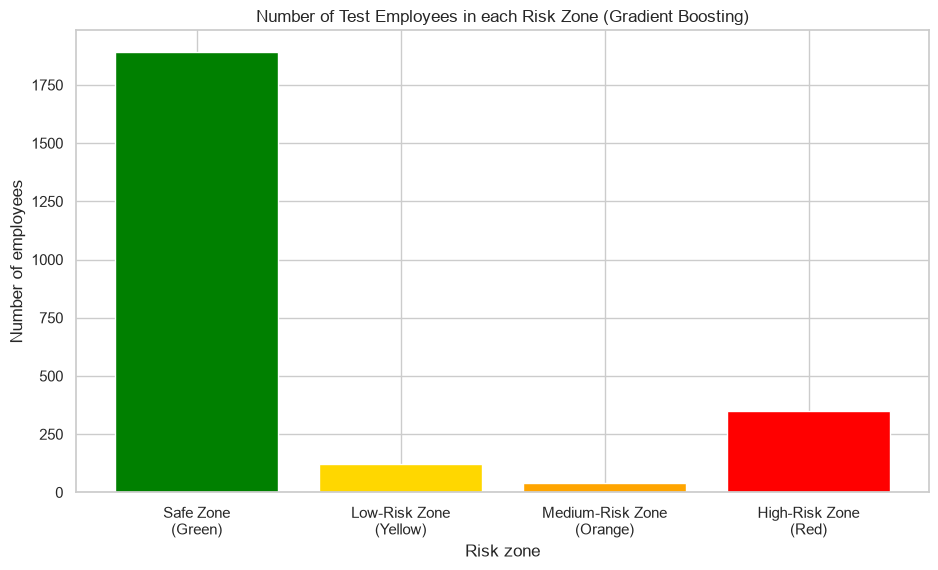

In [33]:
# Bar chart of the number of test employees in each risk zone

plt.figure(figsize=(11, 6))
zone_names = [z.replace(' (', '\n(') for z in zone_table.index.astype(str)]
plt.bar(zone_names, zone_table['Employees'], color=['green', 'gold', 'orange', 'red'])
plt.title('Number of Test Employees in each Risk Zone (' + best_name + ')')
plt.xlabel('Risk zone')
plt.ylabel('Number of employees')
plt.show()

Observation:

From the Visualization of the Risk Zone Bar Chart, it is identified the following data and corresponding retention strategy suggested for each category,

- Safe Zone (Green):
    - Data: 
        - 1,890 employees (78.78% of the test set). Only 26 of them actually left (1.38%).
    - Retention Strategy:
        - Keep current engagement: regular one-to-ones, recognition and fair workload (3 to 4 projects).
        - Run yearly satisfaction surveys and the employee feedback will help sort out retention. No special spending is needed.

- Low-Risk Zone (Yellow): 
    - Data:
        - 121 employees (5.04%), with an actual leave rate of 7.44%.
    - Retention Strategy:
        - Workload Check: Managers check in on workload and satisfaction every quarter.
        - Define Goals clearly: Offer training, skill development and clear goals, and watch for movement toward a higher zone.

- Medium-Risk Zone (Orange): 
    - Data:
        - 39 employees (1.63%), with an actual leave rate of 56.41%. They work the longest hours on average (222.97).
    - Retention Strategy:
        - Act soon: Conduct a 1:1 interview when employee is dissatisfied to understand concerns and value them.
        - Rebalance workload (this group has the highest average hours), offer flexible hours, and review pay and promotion eligibility.
        - Agree upon personal development or career plan.

- High-Risk Zone (Red): 
    - Data: 
        - 349 employees (14.55%), with an actual leave rate of 97.71% (341 of 349). Their average satisfaction is the lowest (0.43).
    - Retention Strategy:
        - Act immediately. A senior manager or HR partner from upper management meets each employee within days.
        - Use targeted offers based on the cluster profile: 
            - For overworked high performers, cut projects and hours and give recognition. 
            - For satisfied top performers, offer promotion, a pay review or a new challenge. 
            - For disengaged, under-used staff, offer a role change, training or clear goals.
        - Prepare knowledge transfer and succession plans in case the employee still leaves.

- The actual leave rate rises steadily from zone to zone, so the zones can be used to rank HR action.

## SUMMARY

The goal of this project was to understand why employees leave Portobello Tech, predict who is likely to leave, and suggest retention actions.

### Data quality

- No missing values. 3,008 exact duplicate rows (20.05%) were removed to avoid repeated records leaking between train and test, leaving 11,991 employees (16.6% left).

### Factors linked with turnover (EDA)

- These are associations in past data, not proven causes.
- Low satisfaction has the strongest link with leaving (correlation -0.35 with left).
- Workload follows a U shape: 2 projects (54.17% left) and 6 to 7 projects (44.92% and 100.00% left) are risky, while 3 projects is the safest (1.08%).
- Very long hours (above 280 per month, 72.30% left) and low salary (20.45% left) are also linked with leaving, and promotions are rare among leavers.
- Leaving is not a straight line with years in the company: it peaks at 5 years (45.39%), while 2-year employees rarely leave (1.07%) and no one with 7 or more years left.

### Clusters of employees who left

- Overworked and burned out (534), happy high performers who left (555), and disengaged, under-used staff (902).

### Model results (SMOTE on train only, 5-fold stratified CV)

| Model | CV recall | CV ROC AUC | Test recall | Test precision | Test AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.8292 | 0.8406 | 0.8241 | 0.4095 | 0.8312 |
| Random Forest | 0.9096 | 0.9809 | 0.9020 | 0.9703 | 0.9752 |
| Gradient Boosting | 0.9303 | 0.9856 | 0.9146 | 0.9077 | 0.9769 |

- Recall is the chosen metric, because missing a leaver costs more than a false alarm.
- Best model: Gradient Boosting, with the highest recall and AUC.

### Risk zones (test set, 2,399 employees)

- Safe 1,890 / Low-Risk 121 / Medium-Risk 39 / High-Risk 349. Actual leave rates are 1.38%, 7.44%, 56.41% and 97.71%.

### Recommendations

- Keep workload at 3 to 4 projects and watch for monthly hours above 250.
- Track satisfaction regularly and act when it drops below 0.5.
- Review pay and promotion paths, especially for low-salary staff and employees reaching 4 to 5 years.
- Use the Gradient Boosting risk score each review cycle and focus retention effort on the Red and Orange zones first.